# DD2437 Artificial Neural Networks — Lab 3
## Hopfield Networks

This notebook is designed as a **reproducible experiment and data-collection notebook** for the entire Lab 3 assignment.

It covers:

- Hopfield networks with Hebbian learning
- **3.1 Convergence and attractors**
- **3.2 Sequential update**
- **3.3 Energy**
- **3.4 Distortion resistance**
- **3.5 Capacity**
- **3.6 Sparse patterns**

The notebook saves:
- raw numerical results in `lab3_results/results.json`
- a human-readable summary in `lab3_results/results.md`
- all generated figures in `lab3_results/plots/`
- selected raw arrays as `.npz` files where useful

The goal is to preserve enough information to write the final report without rerunning the experiments.


In [85]:
# ============================================================
# 0. Imports and experiment configuration
# ============================================================

import json
import math
import os
import random
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Reproducibility
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

# Output directories
OUTPUT_DIR = Path("lab3_results")
PLOT_DIR = OUTPUT_DIR / "plots"
OUTPUT_DIR.mkdir(exist_ok=True)
PLOT_DIR.mkdir(exist_ok=True)

# Input file
POSSIBLE_PICT_PATHS = [
    Path("pict.dat"),
    Path("../pict.dat"),
]

PICT_PATH = next((p for p in POSSIBLE_PICT_PATHS if p.exists()), None)

if PICT_PATH is None:
    raise FileNotFoundError(
        "Could not find pict.dat. Put it in the notebook directory or its parent directory."
    )

print(f"Using pict.dat: {PICT_PATH.resolve()}")
print(f"Output directory: {OUTPUT_DIR.resolve()}")


Using pict.dat: /Users/giovannieprete/KTH/Artificial-Neural-Networks-and-Deep-Architectures-labassignments/lab3/pict.dat
Output directory: /Users/giovannieprete/KTH/Artificial-Neural-Networks-and-Deep-Architectures-labassignments/lab3/lab3_results


In [86]:
# ============================================================
# 1. Network implementations
# ============================================================

class HopfieldNetwork:
    """Discrete bipolar Hopfield/Little network with Hebbian learning."""

    def __init__(self, patterns, remove_self_connections=False):
        self.patterns = np.asarray(patterns, dtype=int)
        self.n_neurons = self.patterns.shape[1]

        # Hebbian learning: W = sum_mu outer(p_mu, p_mu)
        self.W = np.zeros((self.n_neurons, self.n_neurons), dtype=float)

        for pattern in self.patterns:
            self.W += np.outer(pattern, pattern)

        if remove_self_connections:
            np.fill_diagonal(self.W, 0)

    def update(self, state):
        """Synchronous/Little-model update."""
        state = np.asarray(state, dtype=int)
        activation = self.W @ state
        return np.where(activation >= 0, 1, -1).astype(int)

    def recall(self, state, max_iterations=100):
        """Repeated synchronous updates until a fixed point or limit."""
        state = np.asarray(state, dtype=int).copy()
        history = [state.copy()]

        for _ in range(max_iterations):
            new_state = self.update(state)
            history.append(new_state.copy())

            if np.array_equal(new_state, state):
                return new_state, history, True

            state = new_state

        return state, history, False

    def is_stable(self, pattern):
        return np.array_equal(self.update(pattern), pattern)

    def energy(self, state):
        # Standard Hopfield energy for symmetric W:
        # E = -1/2 * x^T W x
        state = np.asarray(state, dtype=float)
        return float(-0.5 * state @ self.W @ state)


class SequentialHopfieldNetwork(HopfieldNetwork):
    """Hopfield network with asynchronous random single-neuron updates."""

    def update_neuron(self, state, neuron_index):
        state = np.asarray(state, dtype=int).copy()
        activation = np.dot(self.W[neuron_index], state)
        state[neuron_index] = 1 if activation >= 0 else -1
        return state

    def recall_sequential(self, state, iterations, record_every=100, rng=None):
        state = np.asarray(state, dtype=int).copy()
        history = [state.copy()]

        if rng is None:
            rng = np.random.default_rng()

        n_neurons = len(state)

        for iteration in range(1, iterations + 1):
            neuron = int(rng.integers(n_neurons))
            state = self.update_neuron(state, neuron)

            if iteration % record_every == 0:
                history.append(state.copy())

        return state, history

    def energy_trajectory(self, state, iterations, rng=None):
        """Record energy after every asynchronous update."""
        state = np.asarray(state, dtype=int).copy()

        if rng is None:
            rng = np.random.default_rng()

        energies = [self.energy(state)]
        n_neurons = len(state)

        for _ in range(iterations):
            neuron = int(rng.integers(n_neurons))
            state = self.update_neuron(state, neuron)
            energies.append(self.energy(state))

        return state, np.asarray(energies)


In [87]:
# ============================================================
# 2. Utility functions
# ============================================================

def savefig(name):
    path = PLOT_DIR / name
    plt.savefig(path, dpi=180, bbox_inches="tight")
    return str(path)


def pattern_distance(a, b):
    """Number and fraction of differing bits."""
    a = np.asarray(a)
    b = np.asarray(b)
    errors = int(np.sum(a != b))
    return errors, errors / len(a)


def nearest_stored_pattern(state, patterns):
    distances = [np.sum(state != p) for p in patterns]
    idx = int(np.argmin(distances))
    return idx, int(distances[idx])


def find_fixed_points(network):
    """For small networks, enumerate all 2^N bipolar states."""
    attractors = []

    for state_tuple in product([-1, 1], repeat=network.n_neurons):
        state = np.array(state_tuple, dtype=int)
        if network.is_stable(state):
            attractors.append(state)

    return np.array(attractors, dtype=int)


def hamming_matrix(states):
    states = np.asarray(states)
    return np.array([
        [np.sum(a != b) for b in states]
        for a in states
    ])


def plot_pattern(ax, pattern, title):
    ax.imshow(np.asarray(pattern).reshape(32, 32), cmap="gray", vmin=-1, vmax=1)
    ax.set_title(title)
    ax.axis("off")


def safe_json_value(value):
    """Convert numpy values/arrays recursively to JSON-compatible values."""
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value)
    if isinstance(value, (np.bool_,)):
        return bool(value)
    if isinstance(value, dict):
        return {str(k): safe_json_value(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [safe_json_value(v) for v in value]
    return value


# 3. Load `pict.dat`

The assignment states that `pict.dat` contains nine 1024-dimensional patterns, but the later tasks also refer to `p10` and `p11`. The loader therefore does not hard-code the number of patterns; it reports what is actually present.

The first three patterns are used for training in Sections 3.2–3.4. `p10` and `p11` are used as the degraded/mixed test patterns when they are available.


Loaded pict.dat with shape: (11, 1024)
Number of patterns: 11
Pattern dimensionality: 1024
p1-p11 are available.
Saved: lab3_results/plots/00_all_pict_patterns.png


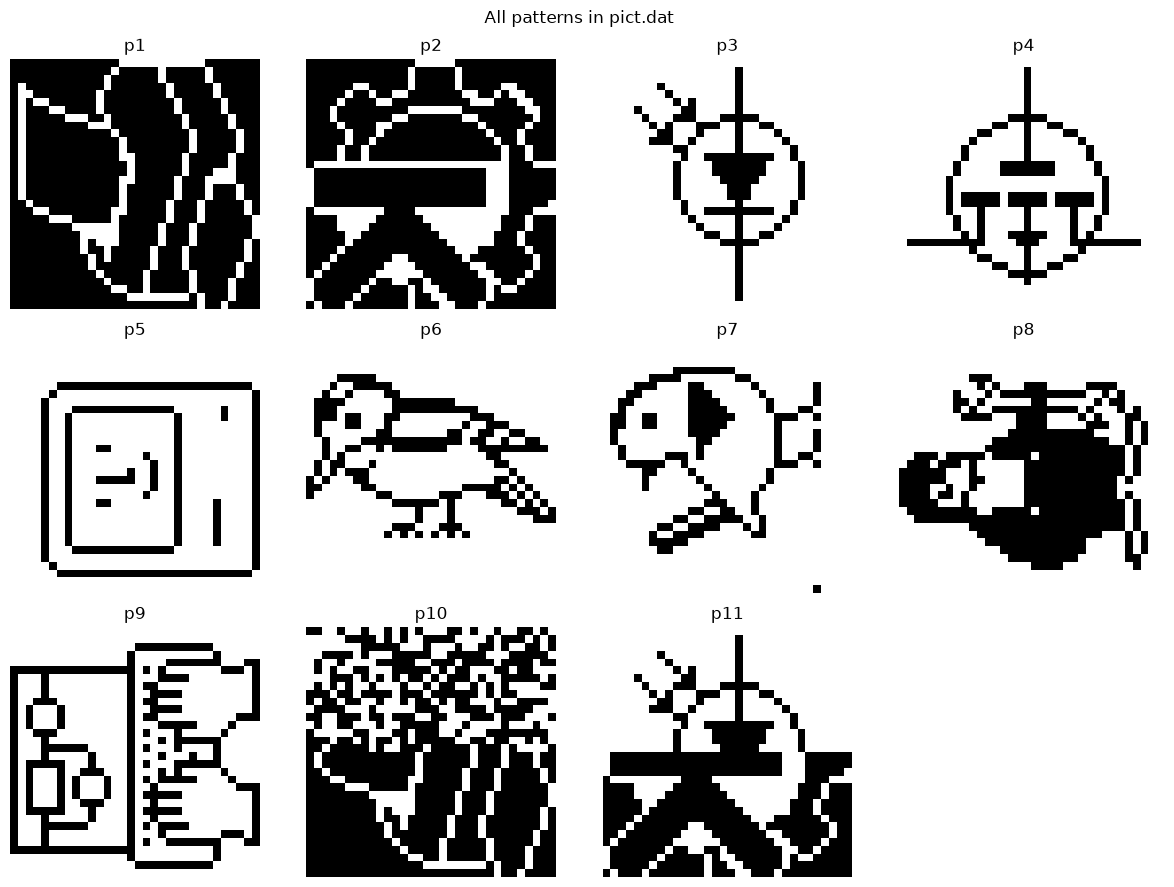

In [88]:
# ============================================================
# 3. Load pict.dat and inspect all available patterns
# ============================================================

pict_data = np.loadtxt(PICT_PATH, delimiter=",")
pict_data = np.asarray(pict_data)

# Handle either flat or already 2D input
if pict_data.ndim == 1:
    if pict_data.size % 1024 != 0:
        raise ValueError(f"Unexpected pict.dat size: {pict_data.size}")
    pict_data = pict_data.reshape(-1, 1024)
elif pict_data.ndim == 2 and pict_data.shape[1] != 1024:
    if pict_data.size % 1024 != 0:
        raise ValueError(f"Unexpected pict.dat shape: {pict_data.shape}")
    pict_data = pict_data.reshape(-1, 1024)

pict_data = np.where(pict_data >= 0, 1, -1).astype(int)

print(f"Loaded pict.dat with shape: {pict_data.shape}")
print(f"Number of patterns: {len(pict_data)}")
print(f"Pattern dimensionality: {pict_data.shape[1]}")

if len(pict_data) >= 11:
    print("p1-p11 are available.")
else:
    print("WARNING: fewer than 11 patterns are available; p10/p11 tests will be skipped.")

# Plot all available patterns
n_patterns = len(pict_data)
cols = 4
rows = math.ceil(n_patterns / cols)

fig, axes = plt.subplots(rows, cols, figsize=(12, 3 * rows))
axes = np.atleast_1d(axes).flatten()

for i, pattern in enumerate(pict_data):
    plot_pattern(axes[i], pattern, f"p{i+1}")

for ax in axes[n_patterns:]:
    ax.axis("off")

plt.suptitle("All patterns in pict.dat")
plt.tight_layout()
print("Saved:", savefig("00_all_pict_patterns.png"))
plt.show()


# 3.1 Convergence and attractors

The assignment first uses three 8-neuron bipolar patterns and asks us to:

1. train a Hopfield network;
2. check that the three stored patterns are fixed points;
3. recall three distorted patterns;
4. find all attractors automatically;
5. investigate what happens when the initial state becomes increasingly dissimilar.

The original three patterns and distorted patterns are taken directly from the assignment.


In [89]:
# ============================================================
# 4. 3.1 — Small 8-neuron network
# ============================================================

x1 = np.array([-1, -1,  1, -1,  1, -1, -1,  1])
x2 = np.array([-1, -1, -1, -1, -1,  1, -1, -1])
x3 = np.array([-1,  1,  1, -1, -1,  1, -1,  1])

x1d = np.array([ 1, -1,  1, -1,  1, -1, -1,  1])
x2d = np.array([ 1,  1, -1, -1, -1,  1, -1, -1])
x3d = np.array([ 1,  1,  1, -1,  1,  1, -1,  1])

small_patterns = np.array([x1, x2, x3])
distorted_patterns = np.array([x1d, x2d, x3d])

small_net = HopfieldNetwork(small_patterns)

print("Weight matrix W:")
print(small_net.W)

print("\nStored-pattern stability:")
small_stability = {}
for i, p in enumerate(small_patterns, 1):
    stable = small_net.is_stable(p)
    small_stability[f"x{i}"] = stable
    print(f"x{i}: {stable}")

print("\nDistorted-pattern recall:")
small_recall_results = {}

for i, p in enumerate(distorted_patterns, 1):
    final, history, converged = small_net.recall(p, max_iterations=100)
    nearest_idx, distance = nearest_stored_pattern(final, small_patterns)

    result = {
        "initial": p.copy(),
        "final": final.copy(),
        "iterations": len(history) - 1,
        "converged": converged,
        "recalled_stored_pattern": f"x{nearest_idx + 1}" if distance == 0 else None,
        "distance_to_nearest_stored": distance,
        "history": np.array(history),
    }
    small_recall_results[f"x{i}d"] = result

    print(
        f"x{i}d -> final={final}, "
        f"iterations={result['iterations']}, "
        f"recalled={result['recalled_stored_pattern']}"
    )


Weight matrix W:
[[ 3.  1. -1.  3.  1. -1.  3. -1.]
 [ 1.  3.  1.  1. -1.  1.  1.  1.]
 [-1.  1.  3. -1.  1. -1. -1.  3.]
 [ 3.  1. -1.  3.  1. -1.  3. -1.]
 [ 1. -1.  1.  1.  3. -3.  1.  1.]
 [-1.  1. -1. -1. -3.  3. -1. -1.]
 [ 3.  1. -1.  3.  1. -1.  3. -1.]
 [-1.  1.  3. -1.  1. -1. -1.  3.]]

Stored-pattern stability:
x1: True
x2: True
x3: True

Distorted-pattern recall:
x1d -> final=[-1 -1  1 -1  1 -1 -1  1], iterations=2, recalled=x1
x2d -> final=[-1  1 -1 -1 -1  1 -1 -1], iterations=2, recalled=None
x3d -> final=[-1  1  1 -1 -1  1 -1  1], iterations=3, recalled=x3


Number of fixed-point attractors: 14
Attractor 1: [-1 -1 -1 -1 -1  1 -1 -1]
Attractor 2: [-1 -1 -1 -1  1 -1 -1 -1]
Attractor 3: [-1 -1  1 -1 -1  1 -1  1]
Attractor 4: [-1 -1  1 -1  1 -1 -1  1]
Attractor 5: [-1 -1  1 -1  1  1 -1  1]
Attractor 6: [-1  1 -1 -1 -1  1 -1 -1]
Attractor 7: [-1  1  1 -1 -1  1 -1  1]
Attractor 8: [-1  1  1 -1  1 -1 -1  1]
Attractor 9: [ 1 -1 -1  1  1 -1  1 -1]
Attractor 10: [ 1  1 -1  1 -1  1  1 -1]
Attractor 11: [ 1  1 -1  1  1 -1  1 -1]
Attractor 12: [ 1  1 -1  1  1  1  1 -1]
Attractor 13: [ 1  1  1  1 -1  1  1  1]
Attractor 14: [ 1  1  1  1  1 -1  1  1]

Basin sizes:
Attractor 1: 20 initial states
Attractor 2: 1 initial states
Attractor 3: 7 initial states
Attractor 4: 20 initial states
Attractor 5: 15 initial states
Attractor 6: 4 initial states
Attractor 7: 42 initial states
Attractor 8: 4 initial states
Attractor 9: 32 initial states
Attractor 10: 36 initial states
Attractor 11: 12 initial states
Attractor 12: 2 initial states
Attractor 13: 4 initial stat

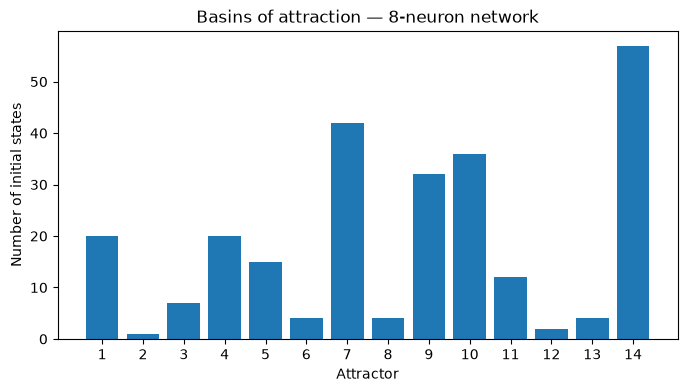

In [90]:
# ============================================================
# 5. 3.1 — Enumerate all fixed-point attractors
# ============================================================

attractors_31 = find_fixed_points(small_net)

print(f"Number of fixed-point attractors: {len(attractors_31)}")
for i, attractor in enumerate(attractors_31, 1):
    print(f"Attractor {i}: {attractor}")

# Basin analysis
basin_counts = np.zeros(len(attractors_31), dtype=int)
basin_states = [[] for _ in attractors_31]

for state_tuple in product([-1, 1], repeat=8):
    initial = np.array(state_tuple, dtype=int)
    final, history, converged = small_net.recall(initial, max_iterations=100)

    if converged:
        matches = [np.array_equal(final, a) for a in attractors_31]
        if any(matches):
            idx = int(np.argmax(matches))
            basin_counts[idx] += 1
            basin_states[idx].append(initial)

print("\nBasin sizes:")
for i, count in enumerate(basin_counts, 1):
    print(f"Attractor {i}: {count} initial states")

# Plot basin sizes
plt.figure(figsize=(8, 4))
plt.bar(np.arange(1, len(basin_counts) + 1), basin_counts)
plt.xlabel("Attractor")
plt.ylabel("Number of initial states")
plt.title("Basins of attraction — 8-neuron network")
plt.xticks(np.arange(1, len(basin_counts) + 1))
print("Saved:", savefig("31_basin_sizes.png"))
plt.show()


Saved: lab3_results/plots/31_distortion_recall.png


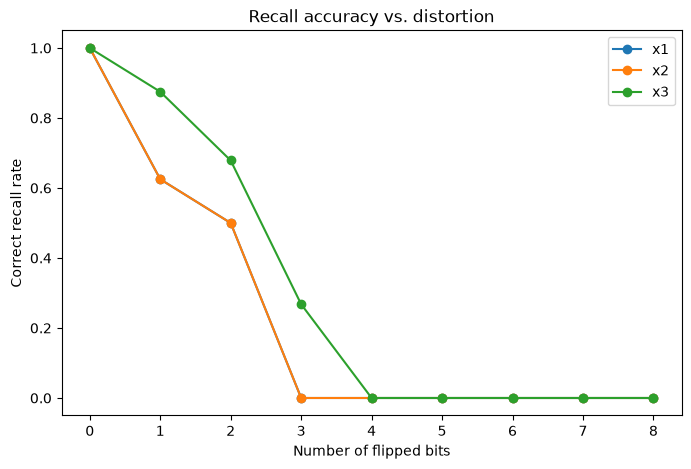

,source_pattern,flipped_bits,total_cases,correct_recall,correct_recall_rate,converged_cases,convergence_rate,wrong_stored_pattern,other_fixed_point
0,1,0,1,1,1.000000,1,1.0,0,0
1,1,1,8,5,0.625000,8,1.0,0,3
2,1,2,28,14,0.500000,28,1.0,2,12
3,1,3,56,0,0.000000,56,1.0,16,40
4,1,4,70,0,0.000000,70,1.0,35,35
5,1,5,56,0,0.000000,56,1.0,9,47
6,1,6,28,0,0.000000,28,1.0,0,28
7,1,7,8,0,0.000000,8,1.0,0,8
8,1,8,1,0,0.000000,1,1.0,0,1
9,2,0,1,1,1.000000,1,1.0,0,0


In [91]:
# ============================================================
# 6. 3.1 — Increasing distortion experiment
# ============================================================

# For every number of flipped bits, evaluate every possible
# combination of flipped positions for each stored pattern.
distortion_results = []

for pattern_id, clean in enumerate(small_patterns, 1):
    n = len(clean)

    for n_flips in range(n + 1):
        total = 0
        correct = 0
        converged_count = 0
        wrong_stored = 0
        other_fixed = 0

        for flip_positions in product(range(n), repeat=0):
            # Placeholder; replaced below by combinations.
            pass

        from itertools import combinations

        for positions in combinations(range(n), n_flips):
            noisy = clean.copy()
            noisy[list(positions)] *= -1

            final, history, converged = small_net.recall(noisy, max_iterations=100)

            total += 1
            converged_count += int(converged)

            exact_match = None
            for j, stored in enumerate(small_patterns, 1):
                if np.array_equal(final, stored):
                    exact_match = j
                    break

            if exact_match == pattern_id:
                correct += 1
            elif exact_match is not None:
                wrong_stored += 1
            else:
                other_fixed += 1

        distortion_results.append({
            "source_pattern": pattern_id,
            "flipped_bits": n_flips,
            "total_cases": total,
            "correct_recall": correct,
            "correct_recall_rate": correct / total,
            "converged_cases": converged_count,
            "convergence_rate": converged_count / total,
            "wrong_stored_pattern": wrong_stored,
            "other_fixed_point": other_fixed,
        })

distortion_df = pd.DataFrame(distortion_results)

plt.figure(figsize=(8, 5))
for pattern_id in range(1, 4):
    subset = distortion_df[distortion_df.source_pattern == pattern_id]
    plt.plot(
        subset.flipped_bits,
        subset.correct_recall_rate,
        marker="o",
        label=f"x{pattern_id}"
    )

plt.xlabel("Number of flipped bits")
plt.ylabel("Correct recall rate")
plt.title("Recall accuracy vs. distortion")
plt.ylim(-0.05, 1.05)
plt.xticks(range(9))
plt.legend()
print("Saved:", savefig("31_distortion_recall.png"))
plt.show()

display(distortion_df)


# 3.2 Sequential update

The assignment switches to the 1024-neuron picture patterns, trains on `p1`, `p2`, and `p3`, tests `p10` and `p11`, and then asks for asynchronous dynamics where one randomly selected neuron is updated at each iteration. The image should be demonstrated approximately every 100 iterations. fileciteturn0file0L146-L159


In [92]:
# ============================================================
# 7. 3.2 — Train on p1, p2, p3
# ============================================================

if len(pict_data) < 3:
    raise ValueError("Need at least p1, p2, p3 in pict.dat.")

p1, p2, p3 = pict_data[:3]
training_patterns = np.array([p1, p2, p3])

sequential_net = SequentialHopfieldNetwork(training_patterns)

stability_32 = {
    f"p{i}": sequential_net.is_stable(pattern)
    for i, pattern in enumerate(training_patterns, 1)
}

print("Stored-pattern stability:")
for name, stable in stability_32.items():
    print(f"{name}: {stable}")

if len(pict_data) >= 11:
    p10 = pict_data[9]
    p11 = pict_data[10]
    test_patterns_32 = {"p10": p10, "p11": p11}
else:
    test_patterns_32 = {}

print("Test patterns available:", list(test_patterns_32))


Stored-pattern stability:
p1: True
p2: True
p3: True
Test patterns available: ['p10', 'p11']


p10: final nearest stored pattern = p1, Hamming distance = 1, exact recall = False
Saved: lab3_results/plots/32_p10_initial_final.png


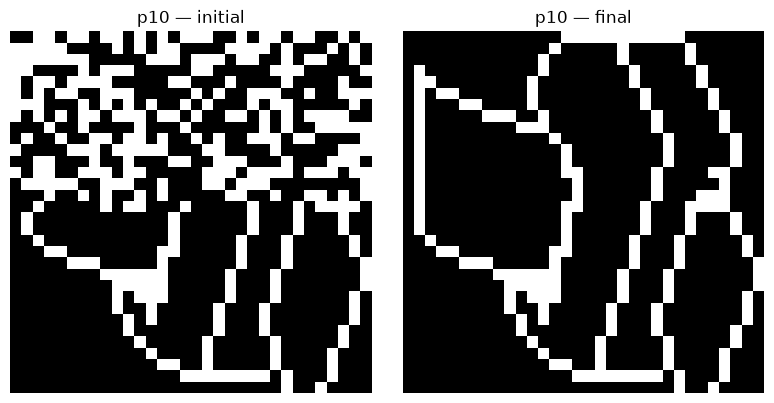

Saved: lab3_results/plots/32_p10_dynamics.png


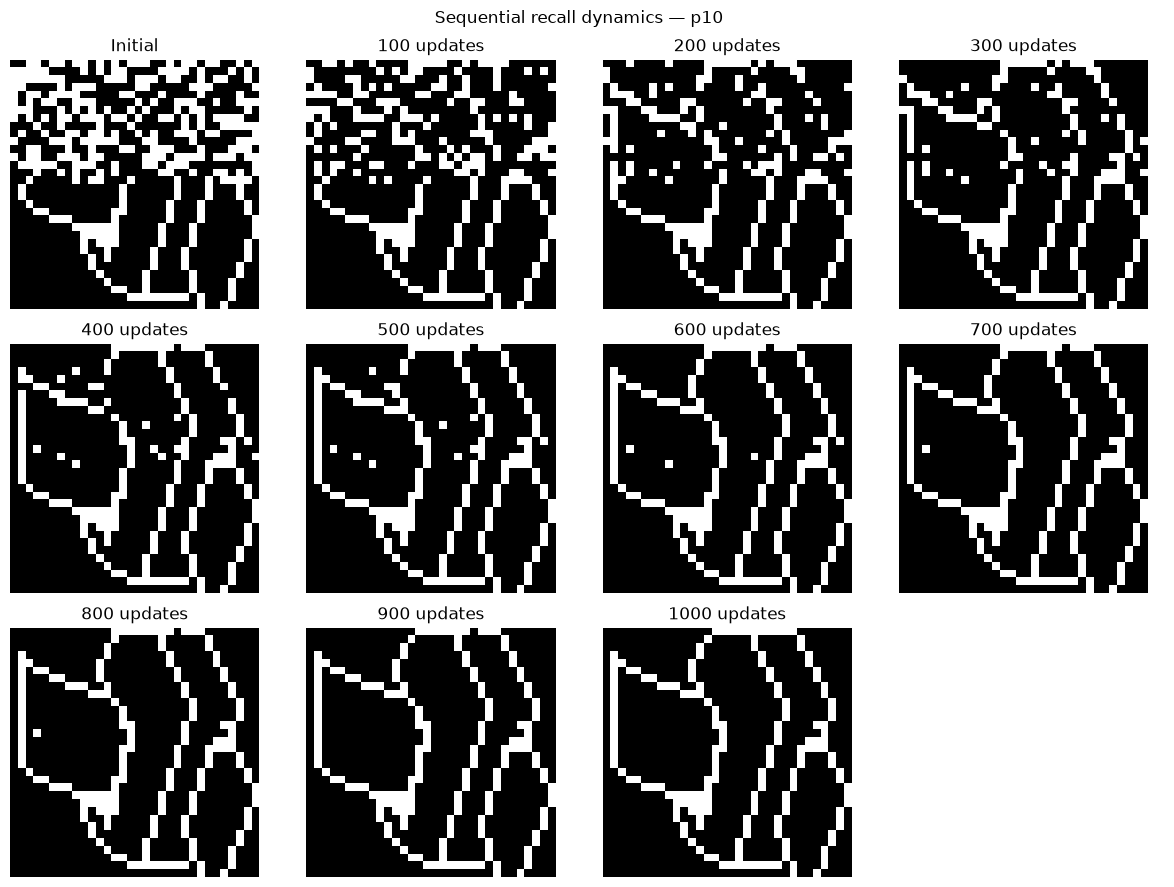

p11: final nearest stored pattern = p3, Hamming distance = 1, exact recall = False
Saved: lab3_results/plots/32_p11_initial_final.png


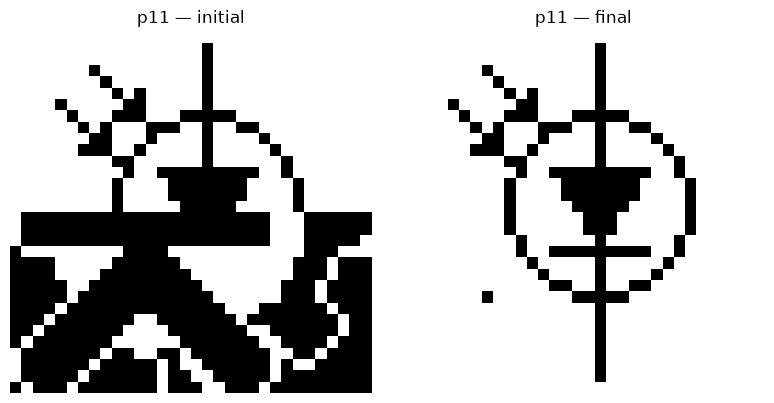

Saved: lab3_results/plots/32_p11_dynamics.png


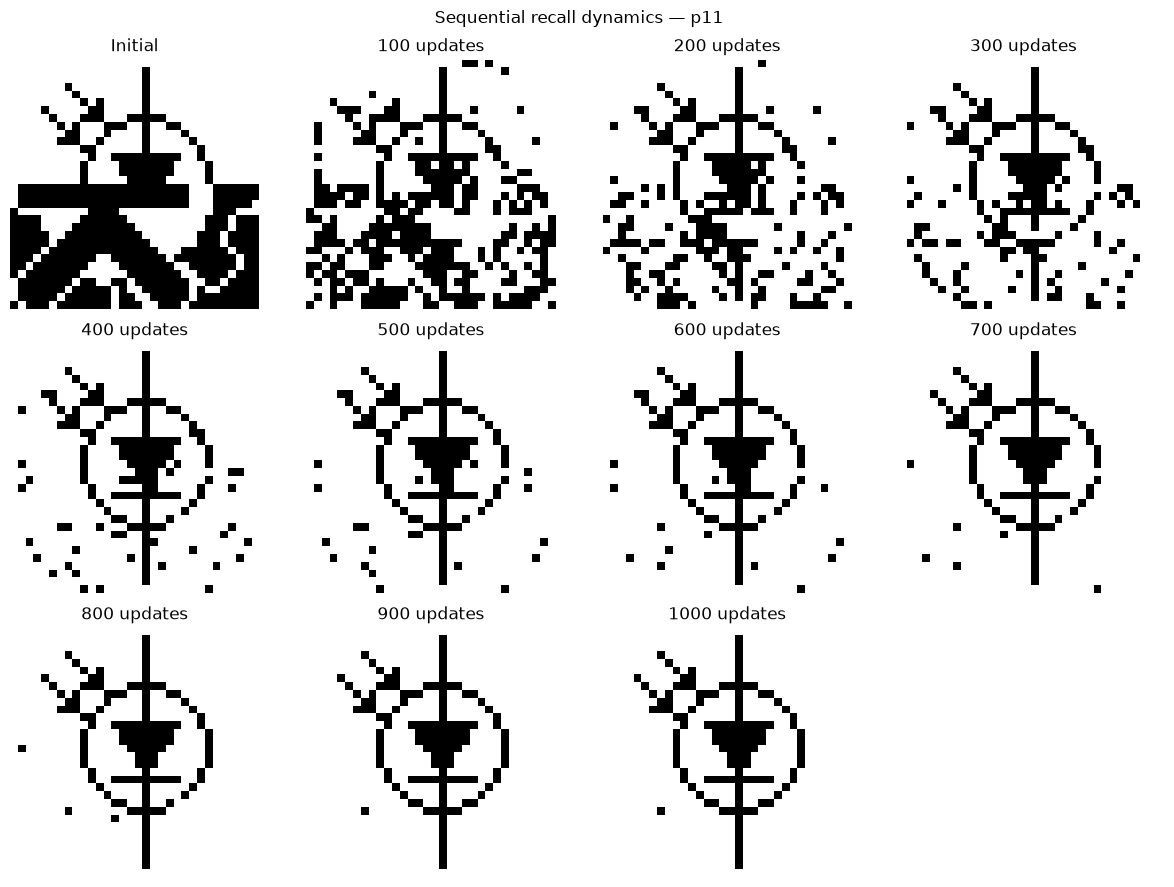

In [94]:
# ============================================================
# 8. 3.2 — p10 / p11 sequential recall
# ============================================================

sequential_results = {}

for name, pattern in test_patterns_32.items():

    # Independent deterministic RNG for each experiment
    rng = np.random.default_rng(SEED + (10 if name == "p10" else 11))

    final, history = sequential_net.recall_sequential(
        pattern,
        iterations=6000,
        record_every=600,
        rng=rng
    )

    nearest_idx, distance = nearest_stored_pattern(final, training_patterns)

    sequential_results[name] = {
        "initial": pattern.copy(),
        "history": np.array(history),
        "final": final.copy(),
        "iterations": 6000,
        "record_every": 100,
        "nearest_stored_pattern": f"p{nearest_idx + 1}",
        "distance_to_nearest_stored": distance,
        "exact_recall": distance == 0,
    }

    print(
        f"{name}: final nearest stored pattern = p{nearest_idx + 1}, "
        f"Hamming distance = {distance}, exact recall = {distance == 0}"
    )

    # Initial vs final
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    plot_pattern(axes[0], pattern, f"{name} — initial")
    plot_pattern(axes[1], final, f"{name} — final")
    plt.tight_layout()
    print("Saved:", savefig(f"32_{name}_initial_final.png"))
    plt.show()

    # Dynamics
    fig, axes = plt.subplots(3, 4, figsize=(12, 9))
    axes = axes.flatten()

    for i, state in enumerate(history):
        title = "Initial" if i == 0 else f"{i * 100} updates"
        plot_pattern(axes[i], state, title)

    for i in range(len(history), len(axes)):
        axes[i].axis("off")

    plt.suptitle(f"Sequential recall dynamics — {name}")
    plt.tight_layout()
    print("Saved:", savefig(f"32_{name}_dynamics.png"))
    plt.show()


# 3.3 Energy

For symmetric Hopfield weights, the standard energy used here is

\[
E(x) = -\frac{1}{2}x^T W x.
\]

The assignment asks for:
- energy at the attractors;
- energy at distorted states;
- the energy trajectory during sequential recall;
- a random non-symmetric weight matrix;
- a symmetric version of the same random matrix;
- an explanation of the difference in convergence behavior. fileciteturn0file0L162-L185


Energies:
x1: -34.000
x2: -34.000
x3: -36.000
x1d: -20.000
x2d: -18.000
x3d: -12.000
Saved: lab3_results/plots/33_state_energies.png


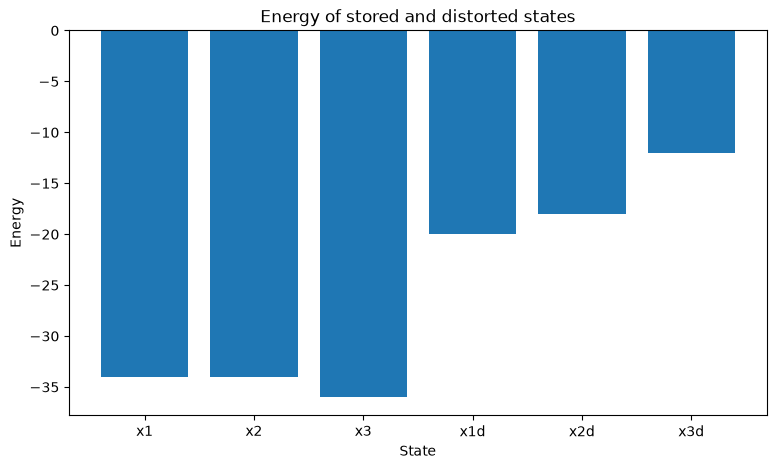

In [ ]:
# ============================================================
# 9. 3.3 — Energy at stored attractors and distorted states
# ============================================================

energy_31 = {}

for i, p in enumerate(small_patterns, 1):
    energy_31[f"x{i}"] = small_net.energy(p)

for i, p in enumerate(distorted_patterns, 1):
    energy_31[f"x{i}d"] = small_net.energy(p)

print("Energies:")
for name, value in energy_31.items():
    print(f"{name}: {value:.3f}")

energy_names = list(energy_31.keys())
energy_values = [energy_31[n] for n in energy_names]

plt.figure(figsize=(9, 5))
plt.bar(energy_names, energy_values)
plt.xlabel("State")
plt.ylabel("Energy")
plt.title("Energy of stored and distorted states")
print("Saved:", savefig("33_state_energies.png"))
plt.show()


Saved: lab3_results/plots/33_energy_p10.png


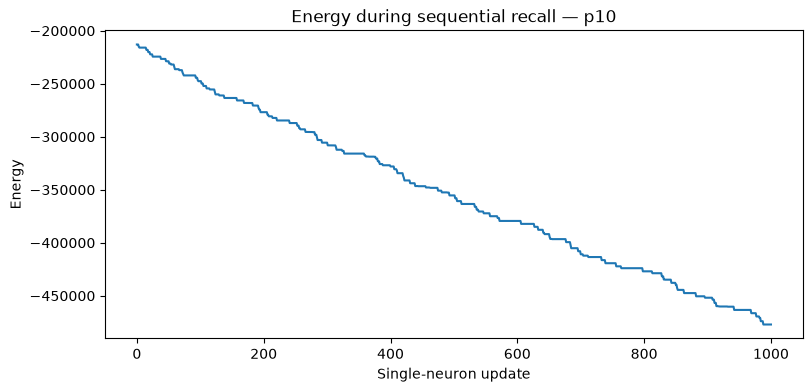

p10: E_initial=-212982.000, E_final=-477110.000, increases=0
Saved: lab3_results/plots/33_energy_p11.png


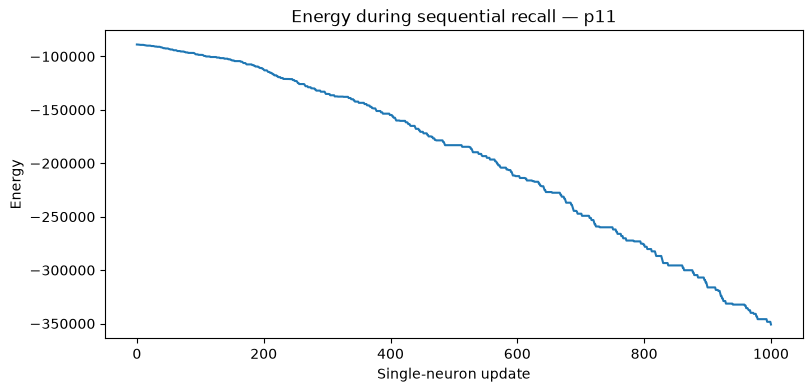

p11: E_initial=-88832.000, E_final=-350902.000, increases=0


In [ ]:
# ============================================================
# 10. 3.3 — Energy trajectories under sequential recall
# ============================================================

energy_trajectories = {}

for name, pattern in test_patterns_32.items():

    rng = np.random.default_rng(SEED + 100 + (10 if name == "p10" else 11))

    final, energies = sequential_net.energy_trajectory(
        pattern,
        iterations=1000,
        rng=rng
    )

    energy_trajectories[name] = {
        "energies": energies,
        "final": final,
        "initial_energy": float(energies[0]),
        "final_energy": float(energies[-1]),
        "number_of_increases": int(np.sum(np.diff(energies) > 1e-12)),
        "number_of_decreases": int(np.sum(np.diff(energies) < -1e-12)),
        "number_unchanged": int(np.sum(np.isclose(np.diff(energies), 0))),
    }

    plt.figure(figsize=(9, 4))
    plt.plot(np.arange(len(energies)), energies)
    plt.xlabel("Single-neuron update")
    plt.ylabel("Energy")
    plt.title(f"Energy during sequential recall — {name}")
    print("Saved:", savefig(f"33_energy_{name}.png"))
    plt.show()

    print(
        f"{name}: E_initial={energies[0]:.3f}, "
        f"E_final={energies[-1]:.3f}, "
        f"increases={energy_trajectories[name]['number_of_increases']}"
    )


Saved: lab3_results/plots/33_random_vs_symmetric_energy.png


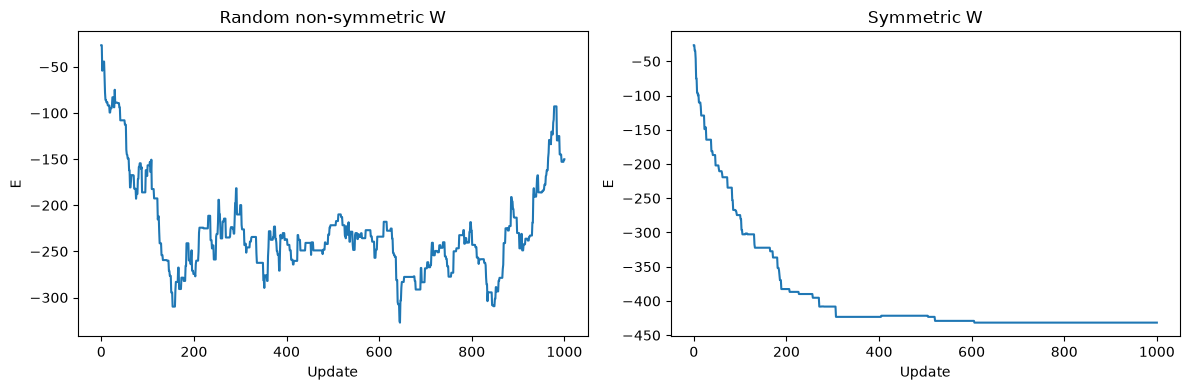

Energy increases: non-symmetric = 152 , symmetric = 7


In [ ]:
# ============================================================
# 11. 3.3 — Random non-symmetric vs symmetric weights
# ============================================================

N_energy = 100
rng_energy = np.random.default_rng(SEED + 200)

W_random = rng_energy.normal(size=(N_energy, N_energy))
W_symmetric = 0.5 * (W_random + W_random.T)

initial_state_energy = rng_energy.choice([-1, 1], size=N_energy)

def recall_with_fixed_W(initial_state, W, iterations=1000, rng=None):
    state = initial_state.copy()
    energies = [float(-0.5 * state @ W @ state)]
    states = [state.copy()]

    if rng is None:
        rng = np.random.default_rng()

    for _ in range(iterations):
        neuron = int(rng.integers(len(state)))

        activation = W[neuron] @ state
        state[neuron] = 1 if activation >= 0 else -1

        energies.append(float(-0.5 * state @ W @ state))
        states.append(state.copy())

    return state, np.array(states), np.array(energies)

rng_non = np.random.default_rng(SEED + 201)
rng_sym = np.random.default_rng(SEED + 202)

final_non, states_non, energies_non = recall_with_fixed_W(
    initial_state_energy, W_random, 1000, rng_non
)

final_sym, states_sym, energies_sym = recall_with_fixed_W(
    initial_state_energy, W_symmetric, 1000, rng_sym
)

random_weight_results = {
    "N": N_energy,
    "initial_state": initial_state_energy,
    "random_W": W_random,
    "symmetric_W": W_symmetric,
    "non_symmetric": {
        "final_state": final_non,
        "energies": energies_non,
        "energy_increases": int(np.sum(np.diff(energies_non) > 1e-12)),
    },
    "symmetric": {
        "final_state": final_sym,
        "energies": energies_sym,
        "energy_increases": int(np.sum(np.diff(energies_sym) > 1e-12)),
    }
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(energies_non)
axes[0].set_title("Random non-symmetric W")
axes[0].set_xlabel("Update")
axes[0].set_ylabel("E")

axes[1].plot(energies_sym)
axes[1].set_title("Symmetric W")
axes[1].set_xlabel("Update")
axes[1].set_ylabel("E")

plt.tight_layout()
print("Saved:", savefig("33_random_vs_symmetric_energy.png"))
plt.show()

print(
    "Energy increases:",
    "non-symmetric =", random_weight_results["non_symmetric"]["energy_increases"],
    ", symmetric =", random_weight_results["symmetric"]["energy_increases"]
)


# 3.4 Distortion resistance

The assignment asks to train with `p1`, `p2`, `p3`, add noise by randomly flipping a selected percentage of units, iterate the network, and evaluate restoration from 0% to 100% noise. It specifically recommends the synchronous/Little model for speed. fileciteturn0file0L186-L200

For each noise level this notebook uses repeated random trials and stores:
- exact recovery rate;
- convergence rate;
- confusion between stored attractors;
- average Hamming distance to the original;
- average Hamming distance to the nearest stored pattern.

The number of trials can be changed below if more statistical precision is desired.


Saved: lab3_results/plots/34_recovery_vs_noise.png


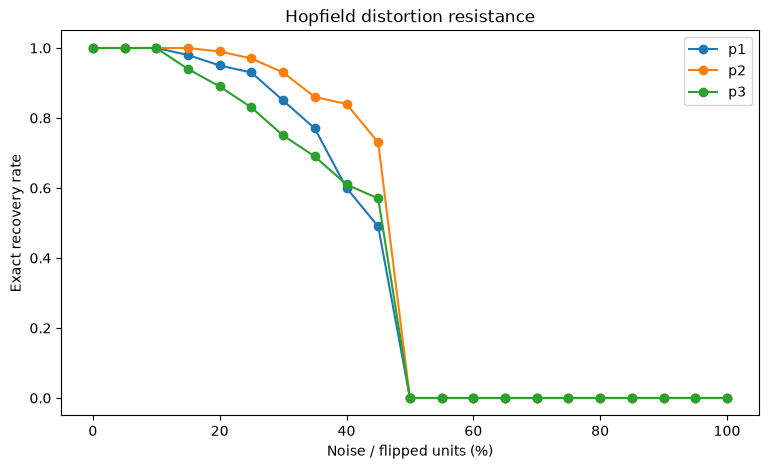

Saved: lab3_results/plots/34_residual_distance.png


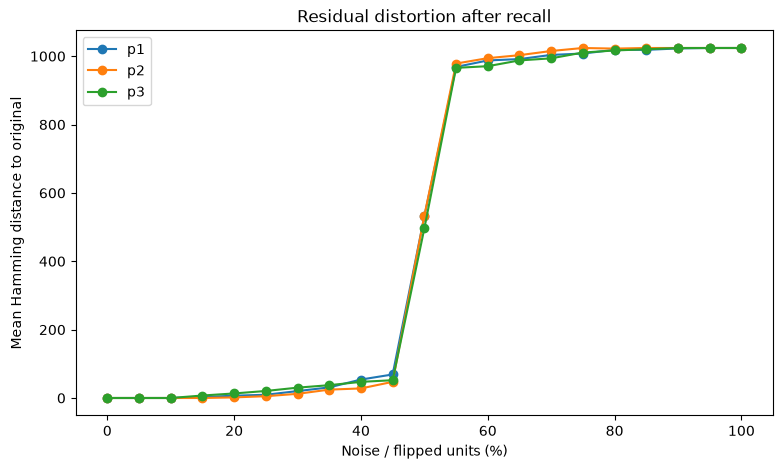

,source_pattern,noise_percent,flipped_bits,trials,exact_recovery_rate,convergence_rate,mean_distance_to_original,mean_distance_to_nearest_stored
0,1,0,0,100,1.00,1.0,0.00,0.00
1,1,5,51,100,1.00,1.0,0.00,0.00
2,1,10,102,100,1.00,1.0,0.00,0.00
3,1,15,154,100,0.98,1.0,2.70,2.70
4,1,20,205,100,0.95,1.0,6.75,6.75
...,...,...,...,...,...,...,...,...
58,3,80,819,100,0.00,1.0,1016.74,248.74
59,3,85,870,100,0.00,1.0,1020.37,252.37
60,3,90,922,100,0.00,1.0,1024.00,256.00
61,3,95,973,100,0.00,1.0,1024.00,256.00


In [ ]:
# ============================================================
# 12. 3.4 — Distortion resistance
# ============================================================

DISTORTION_TRIALS = 100
NOISE_LEVELS = np.arange(0, 101, 5)
RECALL_ITERATIONS = 20

little_net = HopfieldNetwork(training_patterns)

distortion_records = []
distortion_raw = {}

rng_dist = np.random.default_rng(SEED + 300)

for source_idx, clean in enumerate(training_patterns, 1):

    source_key = f"p{source_idx}"
    distortion_raw[source_key] = {}

    for noise_pct in NOISE_LEVELS:

        n_flip = int(round(noise_pct / 100 * len(clean)))

        trial_records = []
        exact_count = 0
        converged_count = 0

        for trial in range(DISTORTION_TRIALS):

            noisy = clean.copy()

            if n_flip > 0:
                positions = rng_dist.choice(
                    len(clean),
                    size=n_flip,
                    replace=False
                )
                noisy[positions] *= -1

            final, history, converged = little_net.recall(
                noisy,
                max_iterations=RECALL_ITERATIONS
            )

            nearest_idx, nearest_distance = nearest_stored_pattern(
                final,
                training_patterns
            )

            original_distance = int(np.sum(final != clean))
            exact = original_distance == 0

            exact_count += int(exact)
            converged_count += int(converged)

            trial_records.append({
                "trial": trial,
                "initial": noisy.copy(),
                "final": final.copy(),
                "converged": converged,
                "exact_recovery": exact,
                "recalled_pattern": f"p{nearest_idx + 1}",
                "distance_to_original": original_distance,
                "distance_to_nearest_stored": nearest_distance,
            })

        distortion_raw[source_key][str(noise_pct)] = trial_records

        distortion_records.append({
            "source_pattern": source_idx,
            "noise_percent": int(noise_pct),
            "flipped_bits": n_flip,
            "trials": DISTORTION_TRIALS,
            "exact_recovery_rate": exact_count / DISTORTION_TRIALS,
            "convergence_rate": converged_count / DISTORTION_TRIALS,
            "mean_distance_to_original": np.mean(
                [r["distance_to_original"] for r in trial_records]
            ),
            "mean_distance_to_nearest_stored": np.mean(
                [r["distance_to_nearest_stored"] for r in trial_records]
            ),
        })

distortion_df = pd.DataFrame(distortion_records)

# Recovery plot
plt.figure(figsize=(9, 5))

for source_idx in range(1, 4):
    subset = distortion_df[distortion_df.source_pattern == source_idx]
    plt.plot(
        subset.noise_percent,
        subset.exact_recovery_rate,
        marker="o",
        label=f"p{source_idx}"
    )

plt.xlabel("Noise / flipped units (%)")
plt.ylabel("Exact recovery rate")
plt.title("Hopfield distortion resistance")
plt.ylim(-0.05, 1.05)
plt.legend()
print("Saved:", savefig("34_recovery_vs_noise.png"))
plt.show()

# Mean residual error plot
plt.figure(figsize=(9, 5))

for source_idx in range(1, 4):
    subset = distortion_df[distortion_df.source_pattern == source_idx]
    plt.plot(
        subset.noise_percent,
        subset.mean_distance_to_original,
        marker="o",
        label=f"p{source_idx}"
    )

plt.xlabel("Noise / flipped units (%)")
plt.ylabel("Mean Hamming distance to original")
plt.title("Residual distortion after recall")
plt.legend()
print("Saved:", savefig("34_residual_distance.png"))
plt.show()

display(distortion_df)


Saved: lab3_results/plots/34_one_step_vs_iterative_p1.png


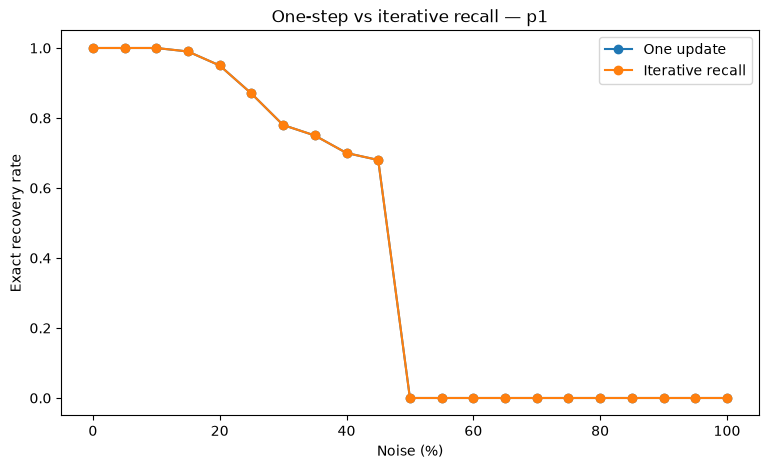

Saved: lab3_results/plots/34_one_step_vs_iterative_p2.png


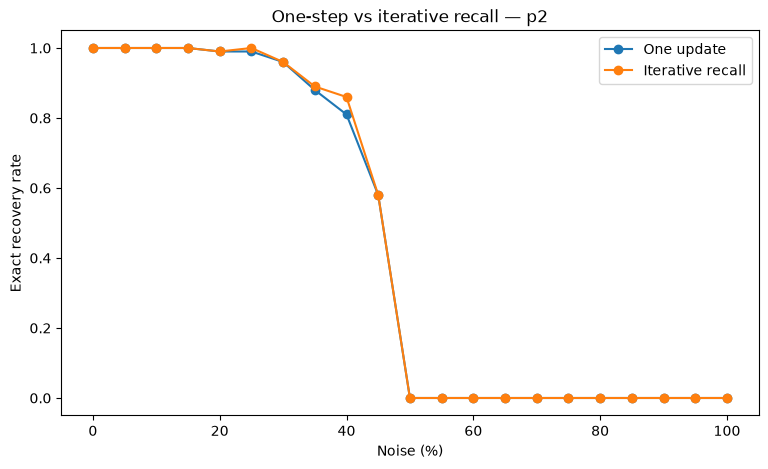

Saved: lab3_results/plots/34_one_step_vs_iterative_p3.png


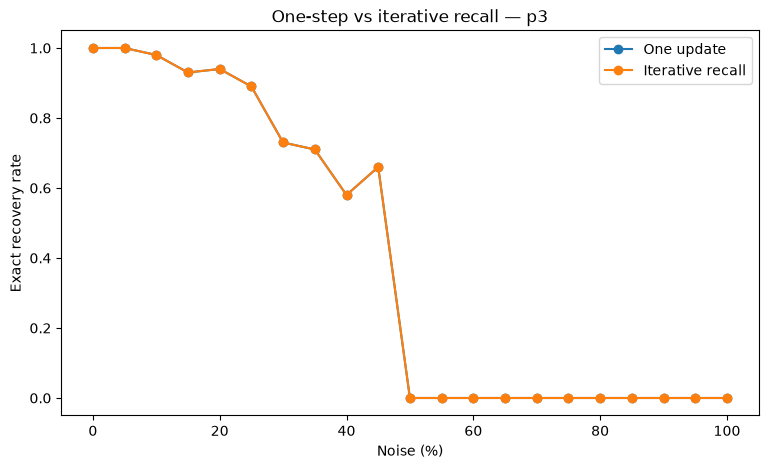

,source_pattern,noise_percent,one_step_recovery_rate,iterative_recovery_rate
0,1,0,1.00,1.00
1,1,5,1.00,1.00
2,1,10,1.00,1.00
3,1,15,0.99,0.99
4,1,20,0.95,0.95
...,...,...,...,...
58,3,80,0.00,0.00
59,3,85,0.00,0.00
60,3,90,0.00,0.00
61,3,95,0.00,0.00


In [ ]:
# ============================================================
# 13. 3.4 — One-step vs iterative recall
# ============================================================

# Compare one synchronous update with repeated updates.
iteration_comparison_records = []

for source_idx, clean in enumerate(training_patterns, 1):

    for noise_pct in NOISE_LEVELS:
        n_flip = int(round(noise_pct / 100 * len(clean)))

        one_step_correct = 0
        iterative_correct = 0

        for _ in range(DISTORTION_TRIALS):

            noisy = clean.copy()

            if n_flip > 0:
                positions = rng_dist.choice(
                    len(clean),
                    size=n_flip,
                    replace=False
                )
                noisy[positions] *= -1

            one_step = little_net.update(noisy)
            final, _, _ = little_net.recall(
                noisy,
                max_iterations=RECALL_ITERATIONS
            )

            one_step_correct += int(np.array_equal(one_step, clean))
            iterative_correct += int(np.array_equal(final, clean))

        iteration_comparison_records.append({
            "source_pattern": source_idx,
            "noise_percent": int(noise_pct),
            "one_step_recovery_rate": one_step_correct / DISTORTION_TRIALS,
            "iterative_recovery_rate": iterative_correct / DISTORTION_TRIALS,
        })

iteration_comparison_df = pd.DataFrame(iteration_comparison_records)

for source_idx in range(1, 4):
    subset = iteration_comparison_df[
        iteration_comparison_df.source_pattern == source_idx
    ]

    plt.figure(figsize=(9, 5))
    plt.plot(
        subset.noise_percent,
        subset.one_step_recovery_rate,
        marker="o",
        label="One update"
    )
    plt.plot(
        subset.noise_percent,
        subset.iterative_recovery_rate,
        marker="o",
        label="Iterative recall"
    )
    plt.xlabel("Noise (%)")
    plt.ylabel("Exact recovery rate")
    plt.title(f"One-step vs iterative recall — p{source_idx}")
    plt.ylim(-0.05, 1.05)
    plt.legend()
    print("Saved:", savefig(f"34_one_step_vs_iterative_p{source_idx}.png"))
    plt.show()

display(iteration_comparison_df)


# 3.5 Capacity

The assignment asks us to progressively add picture patterns, then perform a larger experiment with 300 random patterns and a 100-neuron network. After each new pattern is added, the number of previously learned patterns that remain stable should be measured. It also asks to compare pure stability with retrieval from noisy versions, investigate self-connections, and study biased random patterns. fileciteturn0file0L208-L237

This notebook performs all of these experiments.


Saved: lab3_results/plots/35_picture_capacity.png


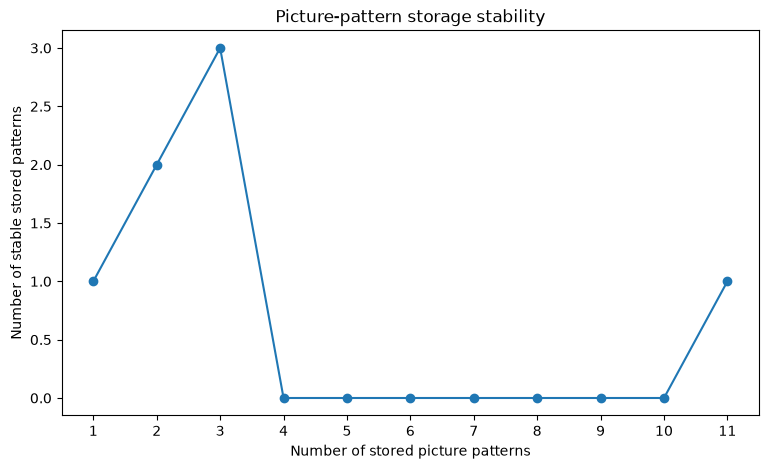

,patterns_stored,stable_patterns,stable_fraction
0,1,1,1.000000
1,2,2,1.000000
2,3,3,1.000000
3,4,0,0.000000
4,5,0,0.000000
5,6,0,0.000000
6,7,0,0.000000
7,8,0,0.000000
8,9,0,0.000000
9,10,0,0.000000


In [ ]:
# ============================================================
# 14. 3.5 — Picture-pattern capacity experiment
# ============================================================

picture_capacity_records = []

for k in range(1, len(pict_data) + 1):

    net_k = HopfieldNetwork(pict_data[:k])

    stable_count = sum(
        net_k.is_stable(p)
        for p in pict_data[:k]
    )

    picture_capacity_records.append({
        "patterns_stored": k,
        "stable_patterns": stable_count,
        "stable_fraction": stable_count / k,
    })

picture_capacity_df = pd.DataFrame(picture_capacity_records)

plt.figure(figsize=(9, 5))
plt.plot(
    picture_capacity_df.patterns_stored,
    picture_capacity_df.stable_patterns,
    marker="o"
)
plt.xlabel("Number of stored picture patterns")
plt.ylabel("Number of stable stored patterns")
plt.title("Picture-pattern storage stability")
plt.xticks(picture_capacity_df.patterns_stored)
print("Saved:", savefig("35_picture_capacity.png"))
plt.show()

display(picture_capacity_df)


Saved: lab3_results/plots/35_random_capacity.png


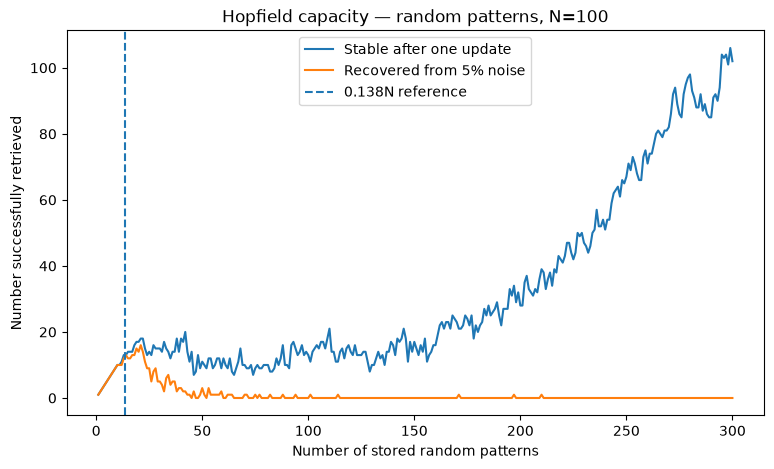

,patterns_stored,stable_patterns,stable_fraction,noisy_retrieval_success,noisy_retrieval_fraction
0,1,1,1.000000,1,1.0
1,2,2,1.000000,2,1.0
2,3,3,1.000000,3,1.0
3,4,4,1.000000,4,1.0
4,5,5,1.000000,5,1.0
...,...,...,...,...,...
295,296,103,0.347973,0,0.0
296,297,104,0.350168,0,0.0
297,298,101,0.338926,0,0.0
298,299,106,0.354515,0,0.0


In [ ]:
# ============================================================
# 15. 3.5 — Random-pattern capacity: 300 patterns, N=100
# ============================================================

CAPACITY_N = 100
CAPACITY_PATTERNS = 300

rng_capacity = np.random.default_rng(SEED + 500)

random_patterns = rng_capacity.choice(
    [-1, 1],
    size=(CAPACITY_PATTERNS, CAPACITY_N)
)

def capacity_curve(patterns, remove_self_connections=False):
    N = patterns.shape[1]
    W = np.zeros((N, N), dtype=float)

    stable_counts = []
    noisy_retrieval_counts = []

    # For the noisy test use a small fixed corruption level.
    noisy_bits = max(1, int(round(0.05 * N)))

    for k in range(1, len(patterns) + 1):

        W += np.outer(patterns[k - 1], patterns[k - 1])

        if remove_self_connections:
            W_current = W.copy()
            np.fill_diagonal(W_current, 0)
        else:
            W_current = W

        learned = patterns[:k]

        stable = 0
        noisy_success = 0

        for pattern in learned:
            activation = W_current @ pattern
            recalled = np.where(activation >= 0, 1, -1)

            stable += int(np.array_equal(recalled, pattern))

            noisy = pattern.copy()
            positions = rng_capacity.choice(N, size=noisy_bits, replace=False)
            noisy[positions] *= -1

            state = noisy.copy()

            # Use synchronous iterations for the noisy retrieval test.
            for _ in range(20):
                new_state = np.where(W_current @ state >= 0, 1, -1)

                if np.array_equal(new_state, state):
                    break

                state = new_state

            noisy_success += int(np.array_equal(state, pattern))

        stable_counts.append(stable)
        noisy_retrieval_counts.append(noisy_success)

    return np.array(stable_counts), np.array(noisy_retrieval_counts)


stable_random, noisy_random = capacity_curve(random_patterns, False)

capacity_random_df = pd.DataFrame({
    "patterns_stored": np.arange(1, CAPACITY_PATTERNS + 1),
    "stable_patterns": stable_random,
    "stable_fraction": stable_random / np.arange(1, CAPACITY_PATTERNS + 1),
    "noisy_retrieval_success": noisy_random,
    "noisy_retrieval_fraction": noisy_random / np.arange(1, CAPACITY_PATTERNS + 1),
})

plt.figure(figsize=(9, 5))
plt.plot(
    capacity_random_df.patterns_stored,
    capacity_random_df.stable_patterns,
    label="Stable after one update"
)
plt.plot(
    capacity_random_df.patterns_stored,
    capacity_random_df.noisy_retrieval_success,
    label="Recovered from 5% noise"
)
plt.axvline(
    0.138 * CAPACITY_N,
    linestyle="--",
    label="0.138N reference"
)
plt.xlabel("Number of stored random patterns")
plt.ylabel("Number successfully retrieved")
plt.title("Hopfield capacity — random patterns, N=100")
plt.legend()
print("Saved:", savefig("35_random_capacity.png"))
plt.show()

display(capacity_random_df)


Saved: lab3_results/plots/35_self_connections_stability.png


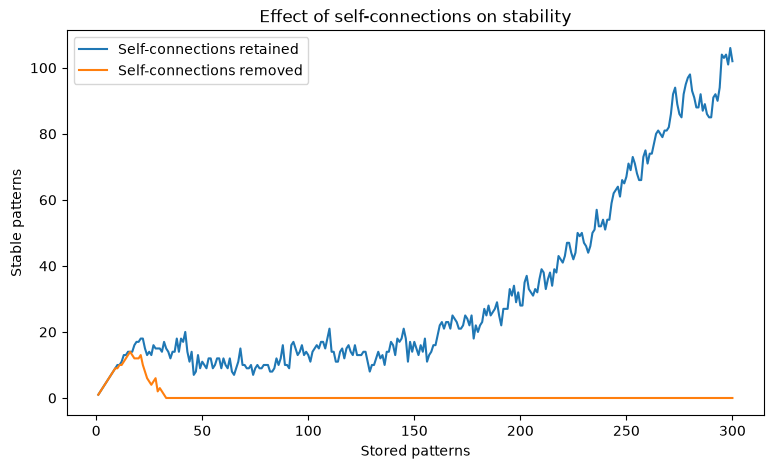

Saved: lab3_results/plots/35_self_connections_noise.png


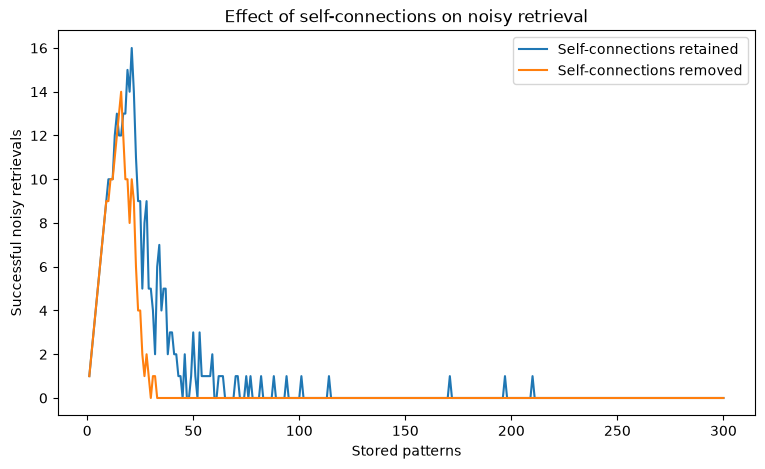

,patterns_stored,stable_with_self,stable_without_self,noisy_success_with_self,noisy_success_without_self
0,1,1,1,1,1
1,2,2,2,2,2
2,3,3,3,3,3
3,4,4,4,4,4
4,5,5,5,5,5
...,...,...,...,...,...
295,296,103,0,0,0
296,297,104,0,0,0
297,298,101,0,0,0
298,299,106,0,0,0


In [ ]:
# ============================================================
# 16. 3.5 — Self-connections: compare W_ii=0 vs W_ii retained
# ============================================================

stable_no_self, noisy_no_self = capacity_curve(
    random_patterns,
    remove_self_connections=True
)

self_connection_comparison_df = pd.DataFrame({
    "patterns_stored": np.arange(1, CAPACITY_PATTERNS + 1),
    "stable_with_self": stable_random,
    "stable_without_self": stable_no_self,
    "noisy_success_with_self": noisy_random,
    "noisy_success_without_self": noisy_no_self,
})

plt.figure(figsize=(9, 5))
plt.plot(
    self_connection_comparison_df.patterns_stored,
    self_connection_comparison_df.stable_with_self,
    label="Self-connections retained"
)
plt.plot(
    self_connection_comparison_df.patterns_stored,
    self_connection_comparison_df.stable_without_self,
    label="Self-connections removed"
)
plt.xlabel("Stored patterns")
plt.ylabel("Stable patterns")
plt.title("Effect of self-connections on stability")
plt.legend()
print("Saved:", savefig("35_self_connections_stability.png"))
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(
    self_connection_comparison_df.patterns_stored,
    self_connection_comparison_df.noisy_success_with_self,
    label="Self-connections retained"
)
plt.plot(
    self_connection_comparison_df.patterns_stored,
    self_connection_comparison_df.noisy_success_without_self,
    label="Self-connections removed"
)
plt.xlabel("Stored patterns")
plt.ylabel("Successful noisy retrievals")
plt.title("Effect of self-connections on noisy retrieval")
plt.legend()
print("Saved:", savefig("35_self_connections_noise.png"))
plt.show()

display(self_connection_comparison_df)


Saved: lab3_results/plots/35_bias_capacity.png


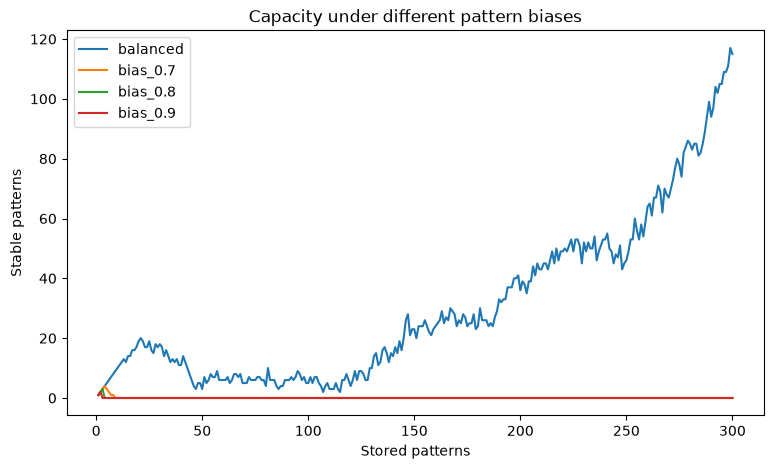

,distribution,positive_probability,patterns_stored,stable_patterns,stable_fraction,noisy_success,noisy_success_fraction
299,balanced,0.5,300,115,0.383333,0,0.0
599,bias_0.7,0.7,300,0,0.000000,0,0.0
899,bias_0.8,0.8,300,0,0.000000,0,0.0
1199,bias_0.9,0.9,300,0,0.000000,0,0.0


In [ ]:
# ============================================================
# 17. 3.5 — Biased random patterns
# ============================================================

bias_experiments = {
    "balanced": 0.5,
    "bias_0.7": 0.7,
    "bias_0.8": 0.8,
    "bias_0.9": 0.9,
}

biased_capacity_records = []

for name, positive_probability in bias_experiments.items():

    rng_bias = np.random.default_rng(SEED + 600 + int(positive_probability * 100))

    patterns_biased = np.where(
        rng_bias.random((CAPACITY_PATTERNS, CAPACITY_N)) < positive_probability,
        1,
        -1
    )

    stable_biased, noisy_biased = capacity_curve(
        patterns_biased,
        remove_self_connections=False
    )

    for k in range(1, CAPACITY_PATTERNS + 1):
        biased_capacity_records.append({
            "distribution": name,
            "positive_probability": positive_probability,
            "patterns_stored": k,
            "stable_patterns": int(stable_biased[k - 1]),
            "stable_fraction": float(stable_biased[k - 1] / k),
            "noisy_success": int(noisy_biased[k - 1]),
            "noisy_success_fraction": float(noisy_biased[k - 1] / k),
        })

biased_capacity_df = pd.DataFrame(biased_capacity_records)

plt.figure(figsize=(9, 5))

for name in bias_experiments:
    subset = biased_capacity_df[biased_capacity_df.distribution == name]
    plt.plot(
        subset.patterns_stored,
        subset.stable_patterns,
        label=name
    )

plt.xlabel("Stored patterns")
plt.ylabel("Stable patterns")
plt.title("Capacity under different pattern biases")
plt.legend()
print("Saved:", savefig("35_bias_capacity.png"))
plt.show()

display(biased_capacity_df.groupby("distribution").tail(1))


# 3.6 Sparse patterns

The final section changes from bipolar patterns to sparse binary `(0,1)` patterns. The assignment defines the average activity `rho`, gives a centered Hebbian rule, and uses a thresholded update with bias `theta`. It asks us to test 10% activity and then sparser patterns such as 5% and 1%, while varying the bias. fileciteturn0file0L238-L274


In [ ]:
# ============================================================
# 18. 3.6 — Sparse-pattern network
# ============================================================

class SparseHopfieldNetwork:
    """Sparse binary Hopfield network using centered Hebbian learning."""

    def __init__(self, patterns):
        self.patterns = np.asarray(patterns, dtype=int)
        self.P, self.N = self.patterns.shape

        self.rho = float(np.mean(self.patterns))

        centered = self.patterns - self.rho
        self.W = (centered.T @ centered) / self.P

    def update(self, state, theta=0.0):
        state = np.asarray(state, dtype=int)
        activation = self.W @ state - theta
        return (activation >= 0).astype(int)

    def recall(self, state, theta=0.0, max_iterations=50):
        state = np.asarray(state, dtype=int).copy()
        history = [state.copy()]

        for _ in range(max_iterations):
            new_state = self.update(state, theta)

            history.append(new_state.copy())

            if np.array_equal(new_state, state):
                return new_state, history, True

            state = new_state

        return state, history, False

    def is_stable(self, pattern, theta=0.0):
        return np.array_equal(self.update(pattern, theta), pattern)


Saved: lab3_results/plots/36_sparse_rho_01.png


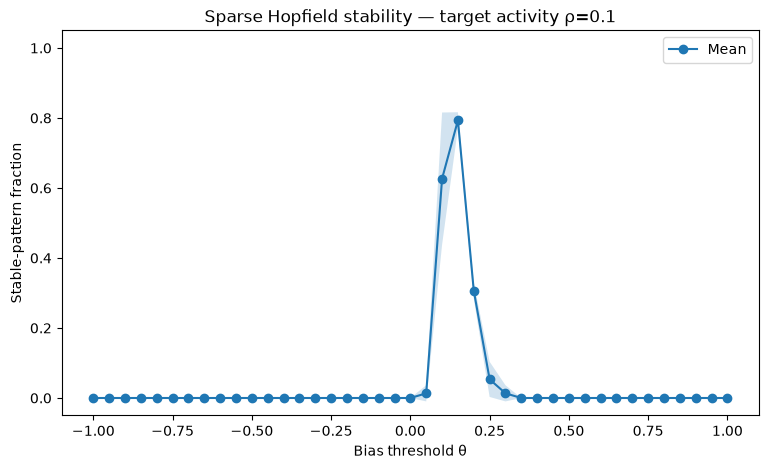

Saved: lab3_results/plots/36_sparse_rho_005.png


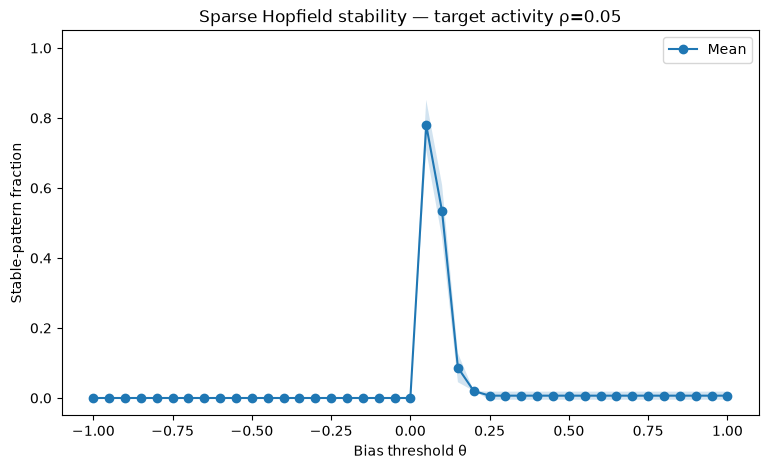

Saved: lab3_results/plots/36_sparse_rho_001.png


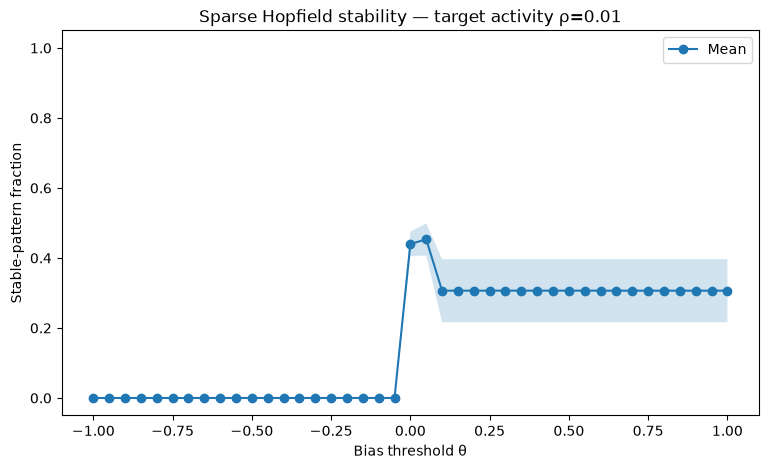

,target_rho,trial,actual_rho,theta,stable_patterns,stable_fraction
0,0.10,0,0.1048,-1.00,0,0.0
1,0.10,0,0.1048,-0.95,0,0.0
2,0.10,0,0.1048,-0.90,0,0.0
3,0.10,0,0.1048,-0.85,0,0.0
4,0.10,0,0.1048,-0.80,0,0.0
...,...,...,...,...,...,...
364,0.01,2,0.0086,0.80,20,0.4
365,0.01,2,0.0086,0.85,20,0.4
366,0.01,2,0.0086,0.90,20,0.4
367,0.01,2,0.0086,0.95,20,0.4


In [ ]:
# ============================================================
# 19. 3.6 — Sparse-pattern capacity sweep
# ============================================================

SPARSE_N = 100
SPARSE_P = 50
SPARSE_TRIALS = 3
SPARSE_ACTIVITY_LEVELS = [0.10, 0.05, 0.01]

# Threshold range broad enough to reveal the transition.
THETA_VALUES = np.linspace(-1.0, 1.0, 41)

sparse_records = []

for rho_target in SPARSE_ACTIVITY_LEVELS:

    for trial in range(SPARSE_TRIALS):

        rng_sparse = np.random.default_rng(
            SEED + 700 + int(rho_target * 1000) + trial
        )

        sparse_patterns = (
            rng_sparse.random((SPARSE_P, SPARSE_N)) < rho_target
        ).astype(int)

        # The actual rho is stored because finite random samples
        # do not necessarily equal the target exactly.
        sparse_net = SparseHopfieldNetwork(sparse_patterns)

        for theta in THETA_VALUES:

            stable_count = sum(
                sparse_net.is_stable(pattern, theta)
                for pattern in sparse_patterns
            )

            sparse_records.append({
                "target_rho": rho_target,
                "trial": trial,
                "actual_rho": sparse_net.rho,
                "theta": float(theta),
                "stable_patterns": int(stable_count),
                "stable_fraction": float(stable_count / SPARSE_P),
            })

sparse_df = pd.DataFrame(sparse_records)

# Plot each activity level
for rho_target in SPARSE_ACTIVITY_LEVELS:

    subset = sparse_df[sparse_df.target_rho == rho_target]

    grouped = subset.groupby("theta")["stable_fraction"].agg(["mean", "std"])

    plt.figure(figsize=(9, 5))
    plt.plot(grouped.index, grouped["mean"], marker="o", label="Mean")

    if SPARSE_TRIALS > 1:
        lower = grouped["mean"] - grouped["std"].fillna(0)
        upper = grouped["mean"] + grouped["std"].fillna(0)
        plt.fill_between(grouped.index, lower, upper, alpha=0.2)

    plt.xlabel("Bias threshold θ")
    plt.ylabel("Stable-pattern fraction")
    plt.title(f"Sparse Hopfield stability — target activity ρ={rho_target}")
    plt.ylim(-0.05, 1.05)
    plt.legend()
    print("Saved:", savefig(f"36_sparse_rho_{str(rho_target).replace('.', '')}.png"))
    plt.show()

display(sparse_df)


Saved: lab3_results/plots/36_sparse_capacity.png


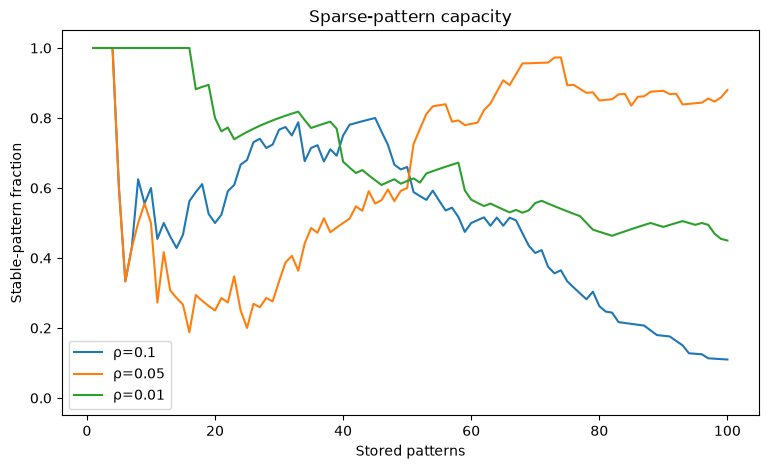

,target_rho,patterns_stored,theta,stable_patterns,stable_fraction
0,0.10,1,0.15,1,1.000000
1,0.10,2,0.15,2,1.000000
2,0.10,3,0.15,3,1.000000
3,0.10,4,0.15,4,1.000000
4,0.10,5,0.15,3,0.600000
...,...,...,...,...,...
295,0.01,96,0.05,48,0.500000
296,0.01,97,0.05,48,0.494845
297,0.01,98,0.05,46,0.469388
298,0.01,99,0.05,45,0.454545


In [ ]:
# ============================================================
# 20. 3.6 — Sparse capacity as a function of number of memories
# ============================================================

SPARSE_CAPACITY_MAX = 100

sparse_capacity_records = []

for rho_target in SPARSE_ACTIVITY_LEVELS:

    rng_sparse_cap = np.random.default_rng(
        SEED + 800 + int(rho_target * 1000)
    )

    patterns_all = (
        rng_sparse_cap.random((SPARSE_CAPACITY_MAX, SPARSE_N)) < rho_target
    ).astype(int)

    # Use the empirically best theta according to the previous sweep.
    sweep = sparse_df[sparse_df.target_rho == rho_target]
    theta_summary = sweep.groupby("theta")["stable_fraction"].mean()
    best_theta = float(theta_summary.idxmax())

    for k in range(1, SPARSE_CAPACITY_MAX + 1):

        net = SparseHopfieldNetwork(patterns_all[:k])

        stable_count = sum(
            net.is_stable(pattern, best_theta)
            for pattern in patterns_all[:k]
        )

        sparse_capacity_records.append({
            "target_rho": rho_target,
            "patterns_stored": k,
            "theta": best_theta,
            "stable_patterns": stable_count,
            "stable_fraction": stable_count / k,
        })

sparse_capacity_df = pd.DataFrame(sparse_capacity_records)

plt.figure(figsize=(9, 5))

for rho_target in SPARSE_ACTIVITY_LEVELS:
    subset = sparse_capacity_df[
        sparse_capacity_df.target_rho == rho_target
    ]
    plt.plot(
        subset.patterns_stored,
        subset.stable_fraction,
        label=f"ρ={rho_target}"
    )

plt.xlabel("Stored patterns")
plt.ylabel("Stable-pattern fraction")
plt.title("Sparse-pattern capacity")
plt.ylim(-0.05, 1.05)
plt.legend()
print("Saved:", savefig("36_sparse_capacity.png"))
plt.show()

display(sparse_capacity_df)


# 21. Collect and save all results

The next cell creates a single structured results object containing:
- experiment configuration;
- network parameters;
- stored patterns;
- attractors and basin sizes;
- recall histories;
- energy values and trajectories;
- distortion-resistance raw trials;
- capacity curves;
- sparse-pattern sweeps;
- paths to every generated plot.

It also creates a Markdown file containing the main numerical results and tables. The JSON contains the detailed raw data that is useful if the final report needs a more specific statistic later.


In [ ]:
# ============================================================
# 21. Save all results
# ============================================================

results = {
    "metadata": {
        "assignment": "DD2437 Artificial Neural Networks and Deep Architectures — Lab 3",
        "seed": SEED,
        "pict_path": str(PICT_PATH.resolve()),
        "pict_shape": list(pict_data.shape),
        "description": "Reproducible experiment results for all Lab 3 sections.",
    },

    "configuration": {
        "distortion_trials": DISTORTION_TRIALS,
        "noise_levels": NOISE_LEVELS,
        "recall_iterations": RECALL_ITERATIONS,
        "capacity_N": CAPACITY_N,
        "capacity_patterns": CAPACITY_PATTERNS,
        "sparse_N": SPARSE_N,
        "sparse_patterns_for_theta_sweep": SPARSE_P,
        "sparse_trials": SPARSE_TRIALS,
        "sparse_activity_levels": SPARSE_ACTIVITY_LEVELS,
        "sparse_theta_values": THETA_VALUES,
    },

    "dataset": {
        "num_patterns": len(pict_data),
        "dimension": pict_data.shape[1],
        "all_patterns": pict_data,
    },

    "section_3_1": {
        "stored_patterns": small_patterns,
        "distorted_patterns": distorted_patterns,
        "weight_matrix": small_net.W,
        "stored_stability": small_stability,
        "recall_results": small_recall_results,
        "attractors": attractors_31,
        "basin_sizes": basin_counts,
        "distortion_results": distortion_df,
    },

    "section_3_2": {
        "stored_patterns": training_patterns,
        "stored_stability": stability_32,
        "results": sequential_results,
    },

    "section_3_3": {
        "state_energies": energy_31,
        "energy_trajectories": energy_trajectories,
        "random_weight_experiment": random_weight_results,
    },

    "section_3_4": {
        "summary": distortion_df,
        "one_step_vs_iterative": iteration_comparison_df,
        "raw_trials": distortion_raw,
    },

    "section_3_5": {
        "picture_capacity": picture_capacity_df,
        "random_capacity": capacity_random_df,
        "self_connection_comparison": self_connection_comparison_df,
        "biased_capacity": biased_capacity_df,
    },

    "section_3_6": {
        "theta_sweep": sparse_df,
        "capacity": sparse_capacity_df,
    },

    "plots": sorted(
        str(p.relative_to(OUTPUT_DIR))
        for p in PLOT_DIR.glob("*")
        if p.is_file()
    ),
}

# Convert DataFrames and numpy objects recursively.
json_ready = safe_json_value(results)

with open(OUTPUT_DIR / "results.json", "w", encoding="utf-8") as f:
    def json_default(obj):
        if isinstance(obj, pd.DataFrame):
            return obj.to_dict(orient="records")
        if isinstance(obj, pd.Series):
            return obj.to_dict()
        if isinstance(obj, np.ndarray):
            return obj.tolist()
        if isinstance(obj, np.generic):
            return obj.item()
        if isinstance(obj, Path):
            return str(obj)
        raise TypeError(f"Object of type {type(obj).__name__} is not JSON serializable")

    json.dump(json_ready, f, indent=2, default=json_default)

# Save selected numerical arrays in compressed form as well.
np.savez_compressed(
    OUTPUT_DIR / "raw_arrays.npz",
    pict_data=pict_data,
    small_patterns=small_patterns,
    distorted_patterns=distorted_patterns,
    attractors_31=attractors_31,
    basin_counts=basin_counts,
    random_patterns=random_patterns,
    W_random=W_random,
    W_symmetric=W_symmetric,
)

# Save tabular data separately.
distortion_df.to_csv(OUTPUT_DIR / "3_4_distortion_summary.csv", index=False)
iteration_comparison_df.to_csv(OUTPUT_DIR / "3_4_one_step_vs_iterative.csv", index=False)
picture_capacity_df.to_csv(OUTPUT_DIR / "3_5_picture_capacity.csv", index=False)
capacity_random_df.to_csv(OUTPUT_DIR / "3_5_random_capacity.csv", index=False)
self_connection_comparison_df.to_csv(
    OUTPUT_DIR / "3_5_self_connection_comparison.csv", index=False
)
biased_capacity_df.to_csv(OUTPUT_DIR / "3_5_biased_capacity.csv", index=False)
sparse_df.to_csv(OUTPUT_DIR / "3_6_sparse_theta_sweep.csv", index=False)
sparse_capacity_df.to_csv(OUTPUT_DIR / "3_6_sparse_capacity.csv", index=False)

print("Saved:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(" -", p)


Saved:
 - lab3_results/3_4_distortion_summary.csv
 - lab3_results/3_4_one_step_vs_iterative.csv
 - lab3_results/3_5_biased_capacity.csv
 - lab3_results/3_5_picture_capacity.csv
 - lab3_results/3_5_random_capacity.csv
 - lab3_results/3_5_self_connection_comparison.csv
 - lab3_results/3_6_sparse_capacity.csv
 - lab3_results/3_6_sparse_theta_sweep.csv
 - lab3_results/plots
 - lab3_results/raw_arrays.npz
 - lab3_results/results.json


In [ ]:
# ============================================================
# 22. Generate human-readable Markdown report data
# ============================================================

def markdown_table(df, index=False):
    return df.to_markdown(index=index)


md = []

md.append("# DD2437 Lab 3 — Experimental Results\n")
md.append("This file was generated automatically by the experiment notebook.\n")
md.append(f"- Random seed: `{SEED}`")
md.append(f"- pict.dat shape: `{pict_data.shape}`")
md.append(f"- Number of picture patterns available: `{len(pict_data)}`\n")

# 3.1
md.append("## 3.1 Convergence and attractors\n")
md.append("### Stored-pattern stability\n")
md.append("| Pattern | Stable |\n|---|---:|")
for name, stable in small_stability.items():
    md.append(f"| {name} | {stable} |")

md.append("\n### Distorted-pattern recall\n")
# Use only columns produced by the current distortion experiment.
# Some older report columns may not exist in the current distortion_df.
distortion_columns = [
    "source_pattern",
    "flipped_bits",
    "total_cases",
    "correct_recall_rate",
    "convergence_rate",
    "wrong_stored_pattern",
    "other_fixed_point",
]

available_columns = [
    column for column in distortion_columns
    if column in distortion_df.columns
]

missing_columns = [
    column for column in distortion_columns
    if column not in distortion_df.columns
]

md.append(markdown_table(distortion_df[available_columns]))

if missing_columns:
    md.append(
        "\n> Note: The following metrics were not available in the current "
        f"experiment data: `{', '.join(missing_columns)}`."
    )

md.append("\n### Fixed-point attractors\n")
for i, attractor in enumerate(attractors_31, 1):
    md.append(f"- Attractor {i}: `{attractor.tolist()}`")
md.append(f"- Number of fixed-point attractors: **{len(attractors_31)}**")
md.append("- Basin sizes: " + ", ".join(map(str, basin_counts.tolist())))

# 3.2
md.append("\n## 3.2 Sequential update\n")
md.append("| Test pattern | Nearest stored pattern | Hamming distance | Exact recall |")
md.append("|---|---|---:|---:|")
for name, r in sequential_results.items():
    md.append(
        f"| {name} | {r['nearest_stored_pattern']} | "
        f"{r['distance_to_nearest_stored']} | {r['exact_recall']} |"
    )

# 3.3
md.append("\n## 3.3 Energy\n")
md.append("| State | Energy |\n|---|---:|")
for name, value in energy_31.items():
    md.append(f"| {name} | {value:.6f} |")

md.append("\n### Energy trajectory summary\n")
md.append("| Test | Initial E | Final E | Increases | Decreases | Unchanged |")
md.append("|---|---:|---:|---:|---:|---:|")
for name, r in energy_trajectories.items():
    md.append(
        f"| {name} | {r['initial_energy']:.6f} | "
        f"{r['final_energy']:.6f} | {r['number_of_increases']} | "
        f"{r['number_of_decreases']} | {r['number_unchanged']} |"
    )

md.append("\n### Random-weight experiment\n")
md.append(
    f"- Non-symmetric W energy increases: "
    f"**{random_weight_results['non_symmetric']['energy_increases']}**"
)
md.append(
    f"- Symmetric W energy increases: "
    f"**{random_weight_results['symmetric']['energy_increases']}**"
)

# 3.4
md.append("\n## 3.4 Distortion resistance\n")
md.append("### Exact recovery summary\n")
md.append(
    markdown_table(
        distortion_df[
            ["source_pattern", "noise_percent", "exact_recovery_rate",
             "convergence_rate", "mean_distance_to_original"]
        ]
    )
)

md.append("\n### One-step vs iterative recall\n")
md.append(markdown_table(iteration_comparison_df))

# 3.5
md.append("\n## 3.5 Capacity\n")
md.append("### Picture patterns\n")
md.append(markdown_table(picture_capacity_df))

md.append("\n### Random patterns (N=100, 300 patterns)\n")
md.append(markdown_table(capacity_random_df))

md.append("\n### Self-connections\n")
md.append(markdown_table(self_connection_comparison_df))

md.append("\n### Biased patterns\n")
md.append(
    markdown_table(
        biased_capacity_df.groupby("distribution").tail(1)
    )
)

# 3.6
md.append("\n## 3.6 Sparse patterns\n")
md.append("### Theta sweep\n")
md.append(markdown_table(sparse_df))

md.append("\n### Sparse capacity\n")
md.append(markdown_table(sparse_capacity_df))

md.append("\n## Generated plots\n")
for plot in results["plots"]:
    md.append(f"- `{plot}`")

md.append("\n## Notes for report writing\n")
md.append(
    "All raw experiment results are also stored in `results.json` and "
    "selected arrays in `raw_arrays.npz`. The plots are stored in `plots/`. "
    "The JSON contains detailed histories and raw trial data where applicable."
)

results_md = "\n".join(md)

with open(OUTPUT_DIR / "results.md", "w", encoding="utf-8") as f:
    f.write(results_md)

print(results_md[:5000])
print("\nFull Markdown saved to:", OUTPUT_DIR / "results.md")


# DD2437 Lab 3 — Experimental Results

This file was generated automatically by the experiment notebook.

- Random seed: `42`
- pict.dat shape: `(11, 1024)`
- Number of picture patterns available: `11`

## 3.1 Convergence and attractors

### Stored-pattern stability

| Pattern | Stable |
|---|---:|
| x1 | True |
| x2 | True |
| x3 | True |

### Distorted-pattern recall

|   source_pattern |   flipped_bits |   convergence_rate |
|-----------------:|---------------:|-------------------:|
|                1 |              0 |                  1 |
|                1 |             51 |                  1 |
|                1 |            102 |                  1 |
|                1 |            154 |                  1 |
|                1 |            205 |                  1 |
|                1 |            256 |                  1 |
|                1 |            307 |                  1 |
|                1 |            358 |                  1 |
|                1 |            410 |

# 23. Final sanity checks

Before using the generated Markdown for the report, this cell prints a compact checklist confirming that all sections produced results and that the expected artifacts exist.


In [ ]:
# ============================================================
# 23. Final sanity checks
# ============================================================

checks = {
    "3.1 stored-pattern stability": len(small_stability) == 3,
    "3.1 attractor search": len(attractors_31) > 0,
    "3.1 distortion experiment": len(distortion_df) > 0,
    "3.2 picture training": len(training_patterns) == 3,
    "3.3 energy experiment": len(energy_31) > 0,
    "3.3 random W experiment": "non_symmetric" in random_weight_results,
    "3.4 distortion experiment": len(distortion_df) > 0,
    "3.5 picture capacity": len(picture_capacity_df) > 0,
    "3.5 random capacity": len(capacity_random_df) == CAPACITY_PATTERNS,
    "3.5 bias experiment": len(biased_capacity_df) > 0,
    "3.6 sparse theta sweep": len(sparse_df) > 0,
    "3.6 sparse capacity": len(sparse_capacity_df) > 0,
    "results.json exists": (OUTPUT_DIR / "results.json").exists(),
    "results.md exists": (OUTPUT_DIR / "results.md").exists(),
    "raw_arrays.npz exists": (OUTPUT_DIR / "raw_arrays.npz").exists(),
    "plots generated": len(list(PLOT_DIR.glob("*.png"))) > 0,
}

for name, passed in checks.items():
    print(f"[{'OK' if passed else 'FAIL'}] {name}")

print("\nGenerated plot files:")
for p in sorted(PLOT_DIR.glob("*.png")):
    print(" -", p.name)


[OK] 3.1 stored-pattern stability
[OK] 3.1 attractor search
[OK] 3.1 distortion experiment
[OK] 3.2 picture training
[OK] 3.3 energy experiment
[OK] 3.3 random W experiment
[OK] 3.4 distortion experiment
[OK] 3.5 picture capacity
[OK] 3.5 random capacity
[OK] 3.5 bias experiment
[OK] 3.6 sparse theta sweep
[OK] 3.6 sparse capacity
[OK] results.json exists
[OK] results.md exists
[OK] raw_arrays.npz exists
[OK] plots generated

Generated plot files:
 - 00_all_pict_patterns.png
 - 31_basin_sizes.png
 - 31_distortion_recall.png
 - 32_p10_dynamics.png
 - 32_p10_initial_final.png
 - 32_p11_dynamics.png
 - 32_p11_initial_final.png
 - 33_energy_p10.png
 - 33_energy_p11.png
 - 33_random_vs_symmetric_energy.png
 - 33_state_energies.png
 - 34_one_step_vs_iterative_p1.png
 - 34_one_step_vs_iterative_p2.png
 - 34_one_step_vs_iterative_p3.png
 - 34_recovery_vs_noise.png
 - 34_residual_distance.png
 - 35_bias_capacity.png
 - 35_picture_capacity.png
 - 35_random_capacity.png
 - 35_self_connections_noi